# Customer Segmentation Using ML(K-Means Clustering) 

In [1]:
#importation

#manipulation data
import numpy as np 
import pandas as pd 

#visualisation
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv('customer_segmentation.csv')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [3]:
df.info()
# dtypes: float64(1), int64(25), object(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [4]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

In [5]:
df.shape

(2240, 29)

In [6]:
df.isna().sum()
# nan in column Income 

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [9]:
df.dropna(inplace=True)

In [10]:
df.isna().sum() # elimine the nan by delete it from original dataframe

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
dtype: int64

In [13]:
 df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,...,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.0,2216.0,2216.000000
mean,5588.353339,1968.820397,52247.251354,0.441787,0.505415,49.012635,305.091606,26.356047,166.995939,37.637635,...,5.319043,0.073556,0.074007,0.073105,0.064079,0.013538,0.009477,3.0,11.0,0.150271
std,3249.376275,11.985554,25173.076661,0.536896,0.544181,28.948352,337.327920,39.793917,224.283273,54.752082,...,2.425359,0.261106,0.261842,0.260367,0.244950,0.115588,0.096907,0.0,0.0,0.357417
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2814.750000,1959.000000,35303.000000,0.000000,0.000000,24.000000,24.000000,2.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,174.500000,8.000000,68.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8421.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,505.000000,33.000000,232.250000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


In [15]:
#unique values for Education
df['Education'].value_counts()

Education
Graduation    1116
PhD            481
Master         365
2n Cycle       200
Basic           54
Name: count, dtype: int64

In [16]:
#unique values for Marital_Status
df['Marital_Status'].value_counts() 

Marital_Status
Married     857
Together    573
Single      471
Divorced    232
Widow        76
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [17]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

# Data cleaning & Feature Engeneering  

In [19]:
# convert Dt_Customer this columns from object to datetime
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'],dayfirst=True)

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2216 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2216 non-null   int64         
 1   Year_Birth           2216 non-null   int64         
 2   Education            2216 non-null   object        
 3   Marital_Status       2216 non-null   object        
 4   Income               2216 non-null   float64       
 5   Kidhome              2216 non-null   int64         
 6   Teenhome             2216 non-null   int64         
 7   Dt_Customer          2216 non-null   datetime64[ns]
 8   Recency              2216 non-null   int64         
 9   MntWines             2216 non-null   int64         
 10  MntFruits            2216 non-null   int64         
 11  MntMeatProducts      2216 non-null   int64         
 12  MntFishProducts      2216 non-null   int64         
 13  MntSweetProducts     2216 non-null   i

In [21]:
# calculate age 
df['Age']= 2026 - df['Year_Birth']

In [22]:
df['Age']

0       69
1       72
2       61
3       42
4       45
        ..
2235    59
2236    80
2237    45
2238    70
2239    72
Name: Age, Length: 2216, dtype: int64

In [23]:
# we dont have the total number of children
df['total_children']=df['Kidhome'] + df['Teenhome']

In [24]:
df['total_children']

0       0
1       2
2       0
3       1
4       1
       ..
2235    1
2236    3
2237    0
2238    1
2239    2
Name: total_children, Length: 2216, dtype: int64

In [25]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'Age', 'total_children'],
      dtype='object')

In [26]:
# we dont have total spending 
spending_cols = ['MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds']
df['Total_spending'] = df[spending_cols].sum(axis=1)
df['Total_spending']

0       1617
1         27
2        776
3         53
4        422
        ... 
2235    1341
2236     444
2237    1241
2238     843
2239     172
Name: Total_spending, Length: 2216, dtype: int64

In [27]:
 df['Customer_since']=(pd.Timestamp("today")  - df['Dt_Customer']).dt.days

In [28]:
 df['Customer_since']

0       4905
1       4355
2       4554
3       4381
4       4403
        ... 
2235    4623
2236    4261
2237    4397
2238    4398
2239    4864
Name: Customer_since, Length: 2216, dtype: int64

# EDA

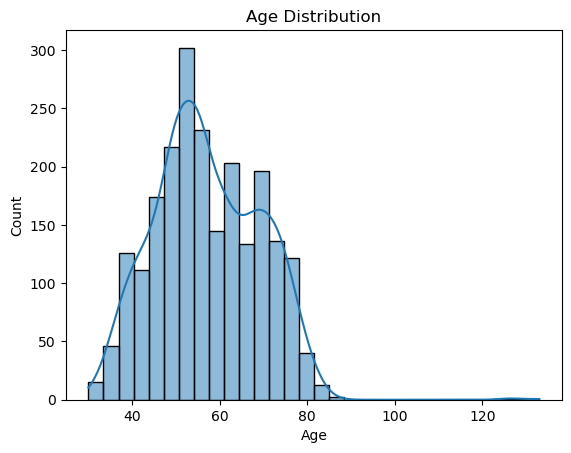

In [29]:
sns.histplot(df['Age'],bins=30, kde=True)
plt.title('Age Distribution')
plt.show() #kinda of normal dist

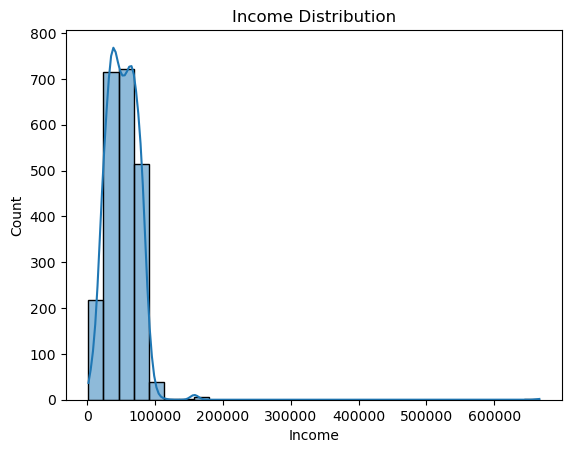

In [30]:
sns.histplot(df['Income'],bins=30, kde=True)
plt.title('Income Distribution')
plt.show() 

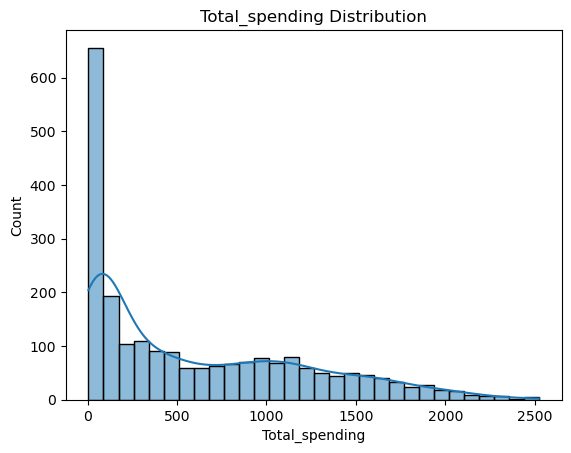

In [32]:
sns.histplot(df['Total_spending'],bins=30, kde=True)
plt.title('Total_spending Distribution')
plt.show() 

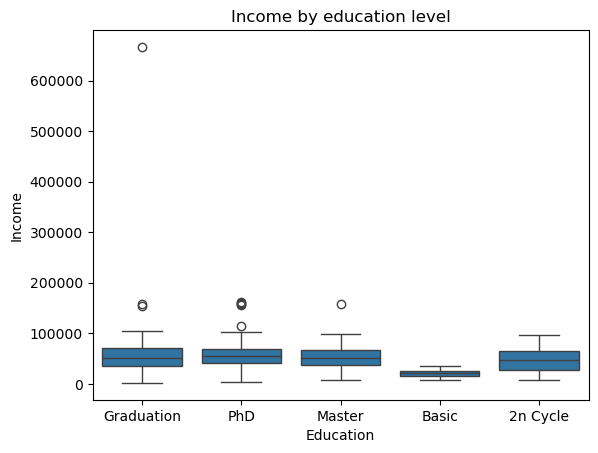

In [33]:
# categories analysis
sns.boxplot(x='Education' , y='Income' ,data=df )
plt.title('Income by education level')
plt.show()

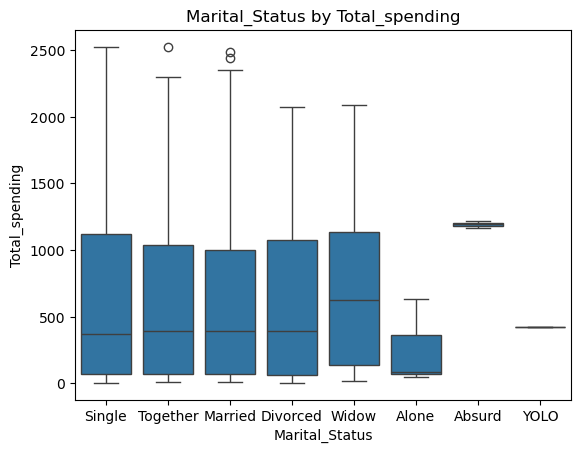

In [35]:
sns.boxplot(x='Marital_Status' , y='Total_spending' ,data=df )
plt.title('Marital_Status by Total_spending')
plt.show()

In [36]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'Age', 'total_children', 'Total_spending', 'Customer_since'],
      dtype='object')

In [39]:
corr = df[[ 'Income','Age','Recency','Total_spending','NumWebPurchases','NumStorePurchases']].corr()

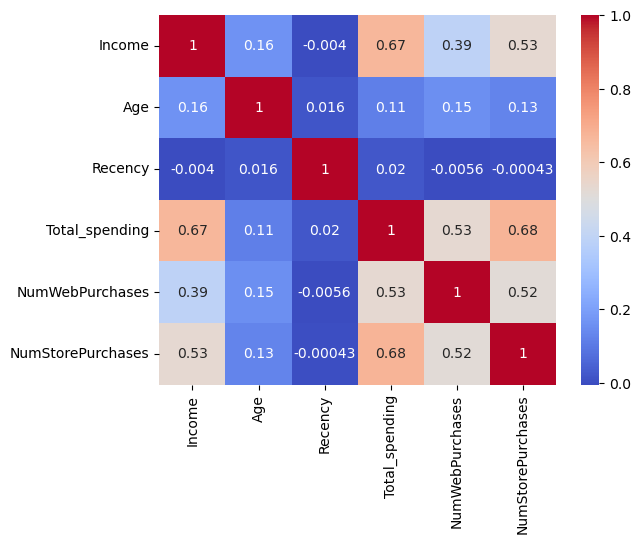

In [41]:
sns.heatmap(corr, annot=True,cmap='coolwarm')
plt.show()

In [45]:
pivot_income = df.pivot_table(
    values='Income',
    index='Education',
    columns='Marital_Status',
    aggfunc='mean'
)


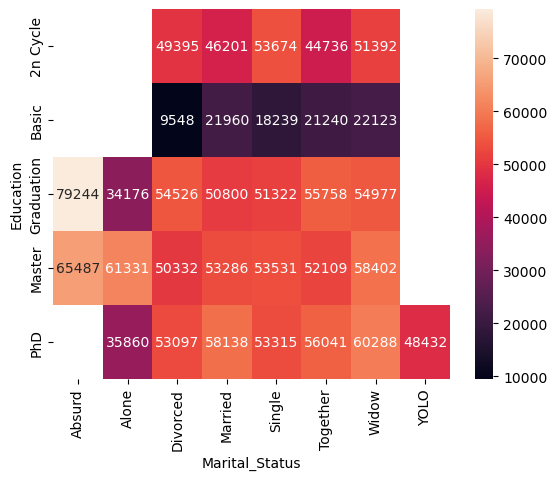

In [47]:
sns.heatmap(pivot_income,fmt='.0f',annot=True)
plt.show()

In [49]:
# spending by education
group1 = df.groupby('Education')['Total_spending'].mean().sort_values(ascending=False)

In [50]:
group1

Education
PhD           676.733888
Graduation    621.686380
Master        609.767123
2n Cycle      494.930000
Basic          81.796296
Name: Total_spending, dtype: float64

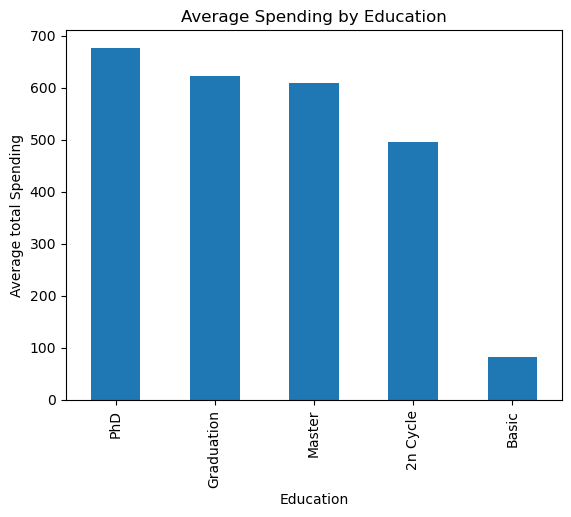

In [51]:
group1.plot(kind='bar')
plt.title('Average Spending by Education')
plt.ylabel('Average total Spending')
plt.show()

In [52]:
df['AcceptedAny']=df[['AcceptedCmp1','AcceptedCmp2','AcceptedCmp3','AcceptedCmp4','AcceptedCmp5','Response']].sum(axis=1)

In [54]:
df['AcceptedAny'].unique()

array([1, 0, 3, 2, 4, 5])

In [55]:
df['AcceptedAny']= df['AcceptedAny'].apply(lambda x:1 if x>0 else 0)

In [56]:
df['AcceptedAny'].unique()

array([1, 0])

In [58]:
group2 = df.groupby('Marital_Status')['AcceptedAny'].mean().sort_values(ascending=False)
group2

Marital_Status
Absurd      0.500000
YOLO        0.500000
Widow       0.342105
Alone       0.333333
Single      0.312102
Divorced    0.297414
Married     0.252042
Together    0.251309
Name: AcceptedAny, dtype: float64

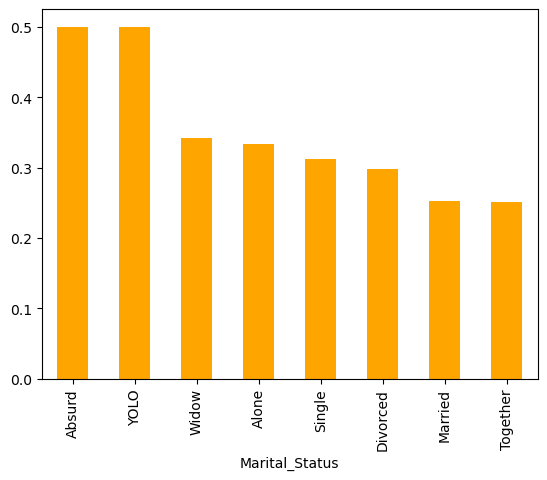

In [59]:
group2.plot(kind='bar', color='orange')
plt.show()

In [60]:
# want to find average Income by groups
bins=[18,30,40,50,60,70,90]
labels=['18-29','30-39','40-49','50-59','60-69','70+']

In [61]:
df['AgeGroup']= pd.cut(df['Age'],bins=bins,labels=labels)
df['AgeGroup']
group3= df.groupby('AgeGroup')['Income'].mean()

C:\Users\hp\AppData\Local\Temp\ipykernel_23032\2619632053.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group3= df.groupby('AgeGroup')['Income'].mean()


In [62]:
group3

AgeGroup
18-29    10960.500000
30-39    47905.475676
40-49    48057.587649
50-59    50479.321534
60-69    55980.030928
70+      58767.083102
Name: Income, dtype: float64

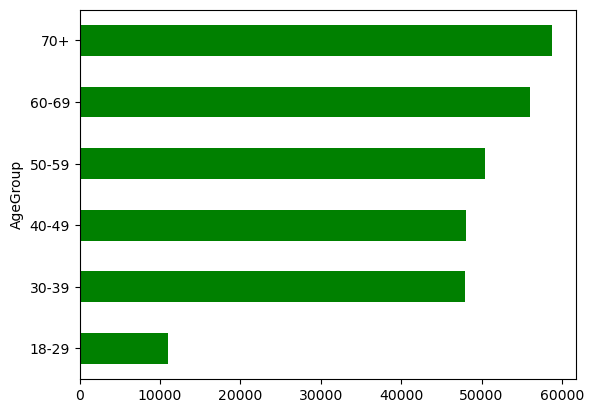

In [65]:
group3.plot(kind='barh', color='green')
plt.show()

In [66]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Complain,Z_CostContact,Z_Revenue,Response,Age,total_children,Total_spending,Customer_since,AcceptedAny,AgeGroup
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,3,11,1,69,0,1617,4905,1,60-69
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,3,11,0,72,2,27,4355,0,70+
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,3,11,0,61,0,776,4554,0,60-69
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,3,11,0,42,1,53,4381,0,40-49
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,3,11,0,45,1,422,4403,0,40-49


In [67]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'Age', 'total_children', 'Total_spending', 'Customer_since',
       'AcceptedAny', 'AgeGroup'],
      dtype='object')

In [70]:
# select the important columns
features = ['Age', 'Income', 'Total_spending', 'NumWebPurchases','NumStorePurchases',
       'NumWebVisitsMonth', 'Recency']

In [71]:
x= df[features].copy()

## ~Preprocessing 

In [72]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
x_sc = scaler.fit_transform(x)
x_sc

array([[ 0.98644293,  0.2340627 ,  1.67548812, ..., -0.55414289,
         0.69323197,  0.31053212],
       [ 1.23680074, -0.23455948, -0.96235832, ..., -1.16951781,
        -0.1315745 , -0.38050944],
       [ 0.31882209,  0.76947764,  0.28024985, ...,  1.29198186,
        -0.54397773, -0.79513438],
       ...,
       [-1.01641959,  0.18809052,  1.05169551, ...,  2.21504423,
         0.28082874,  1.4507507 ],
       [ 1.06989553,  0.67538765,  0.39140438, ...,  1.29198186,
        -0.95638097, -1.41707178],
       [ 1.23680074,  0.02470453, -0.7218    , ..., -0.55414289,
         0.69323197, -0.31140528]], shape=(2216, 7))

## Modelling

In [73]:
from sklearn.cluster import KMeans
wcss =[] # cree une liste 
for i in range(2,10):
    kmeans = KMeans(n_clusters=i) # build model(estimator with hyperparmeter= numb_cluster)
    kmeans.fit(x_sc) # train for each k
    wcss.append(kmeans.inertia_) # ajoute dans la list

In [74]:
wcss

[10218.620143748785,
 9007.786818672808,
 8400.485733129095,
 7635.953950236575,
 7094.5366000546355,
 6603.13596074051,
 6456.564874536792,
 6208.1045696704805]

Text(0, 0.5, 'wcss')

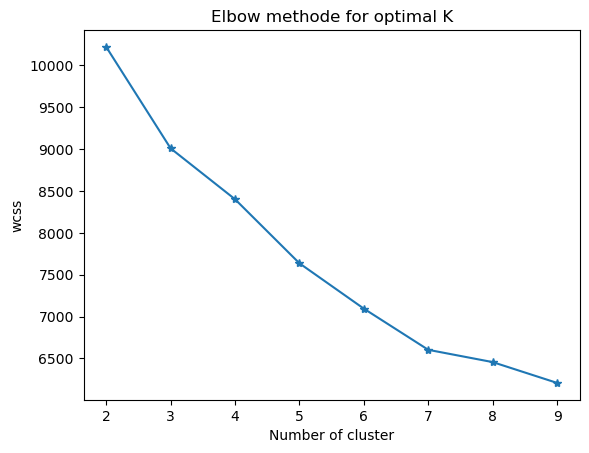

In [75]:
# Elbow methode
plt.plot(range(2,10),wcss, marker='*')
plt.title('Elbow methode for optimal K')
plt.xlabel('Number of cluster')
plt.ylabel('wcss') # k=6 is better

In [76]:
kmeans= KMeans(n_clusters=6)
df['Cluster']=kmeans.fit_predict(x_sc)
df['Cluster']

0       0
1       1
2       0
3       3
4       4
       ..
2235    0
2236    0
2237    5
2238    2
2239    1
Name: Cluster, Length: 2216, dtype: int32

In [77]:
df.head() # gonna give column at the end cluster that tell each ligne which cluster is in 

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Z_CostContact,Z_Revenue,Response,Age,total_children,Total_spending,Customer_since,AcceptedAny,AgeGroup,Cluster
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,3,11,1,69,0,1617,4905,1,60-69,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,3,11,0,72,2,27,4355,0,70+,1
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,3,11,0,61,0,776,4554,0,60-69,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,3,11,0,42,1,53,4381,0,40-49,3
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,3,11,0,45,1,422,4403,0,40-49,4


In [82]:
cluster_summary = df.groupby('Cluster').mean(numeric_only=True)

In [83]:
cluster_summary

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,total_children,Total_spending,Customer_since,AcceptedAny
Cluster,,,,,,,,,,,,,,,,,,,,,
0,5422.523227,1966.405868,60178.819071,0.242054,0.794621,46.650367,549.220049,33.518337,176.547677,44.870416,...,0.024450,0.007335,3.0,11.0,0.195599,59.594132,1.036675,907.195599,4676.369193,0.378973
1,5572.578571,1956.217857,44078.885714,0.464286,0.889286,38.335714,100.939286,7.121429,35.271429,10.728571,...,0.007143,0.007143,3.0,11.0,0.085714,69.782143,1.353571,183.285714,4555.310714,0.160714
2,5792.596923,1955.541538,73544.796923,0.021538,0.403077,52.292308,576.135385,52.996923,368.516923,78.716923,...,0.024615,0.009231,3.0,11.0,0.172308,70.458462,0.424615,1200.753846,4571.443077,0.393846
3,5839.679204,1977.163717,31850.203540,0.831858,0.316372,26.754425,44.444690,5.402655,27.765487,8.106195,...,0.000000,0.015487,3.0,11.0,0.159292,48.836283,1.148230,108.785398,4580.758850,0.210177
4,5395.394299,1973.102138,35130.353919,0.795724,0.448931,79.263658,59.437055,6.494062,31.095012,9.213777,...,0.000000,0.009501,3.0,11.0,0.040380,52.897862,1.244656,133.163895,4583.078385,0.102138
5,5507.802432,1978.723404,78226.303951,0.097264,0.252280,49.665653,580.039514,61.708207,433.343465,87.911854,...,0.030395,0.006079,3.0,11.0,0.255319,47.276596,0.349544,1299.203647,4589.224924,0.422492


In [84]:
df['Cluster'].value_counts()

Cluster
3    452
4    421
0    409
5    329
2    325
1    280
Name: count, dtype: int64

In [85]:
# let's visualise using PCA 

In [86]:
from sklearn.decomposition import PCA
pca= PCA(n_components=2)
pca_data =pca.fit_transform(x_sc)
df['PCA1'],df['PCA2']= pca_data[:,0],pca_data[:,1]

In [87]:
pca_data

array([[ 1.1075188 , -0.21175951],
       [-1.33673385,  0.269839  ],
       [ 1.88227676, -1.01416098],
       ...,
       [ 1.1535966 ,  1.15056999],
       [ 1.88768024, -1.16073698],
       [-0.84182091, -0.15963623]], shape=(2216, 2))

In [88]:
df['PCA1']

0       1.107519
1      -1.336734
2       1.882277
3      -1.784359
4       0.020363
          ...   
2235    1.248177
2236    0.508708
2237    1.153597
2238    1.887680
2239   -0.841821
Name: PCA1, Length: 2216, dtype: float64

In [89]:
df['PCA2']

0      -0.211760
1       0.269839
2      -1.014161
3      -0.704928
4       1.235265
          ...   
2235   -0.535766
2236   -0.141328
2237    1.150570
2238   -1.160737
2239   -0.159636
Name: PCA2, Length: 2216, dtype: float64

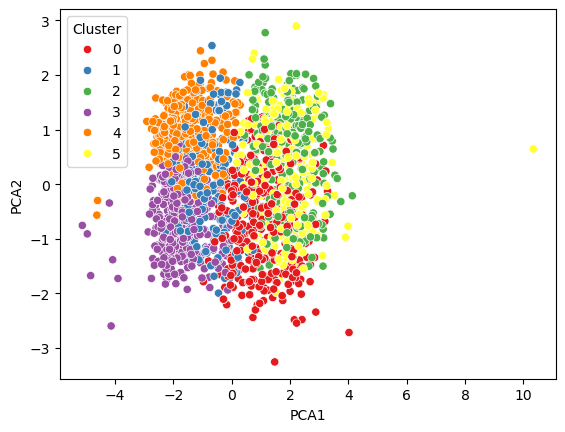

In [90]:
sns.scatterplot(x='PCA1',y='PCA2',hue='Cluster', data=df,palette='Set1')
plt.show()

In [91]:
cluster_summary

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,total_children,Total_spending,Customer_since,AcceptedAny
Cluster,,,,,,,,,,,,,,,,,,,,,
0,5422.523227,1966.405868,60178.819071,0.242054,0.794621,46.650367,549.220049,33.518337,176.547677,44.870416,...,0.024450,0.007335,3.0,11.0,0.195599,59.594132,1.036675,907.195599,4676.369193,0.378973
1,5572.578571,1956.217857,44078.885714,0.464286,0.889286,38.335714,100.939286,7.121429,35.271429,10.728571,...,0.007143,0.007143,3.0,11.0,0.085714,69.782143,1.353571,183.285714,4555.310714,0.160714
2,5792.596923,1955.541538,73544.796923,0.021538,0.403077,52.292308,576.135385,52.996923,368.516923,78.716923,...,0.024615,0.009231,3.0,11.0,0.172308,70.458462,0.424615,1200.753846,4571.443077,0.393846
3,5839.679204,1977.163717,31850.203540,0.831858,0.316372,26.754425,44.444690,5.402655,27.765487,8.106195,...,0.000000,0.015487,3.0,11.0,0.159292,48.836283,1.148230,108.785398,4580.758850,0.210177
4,5395.394299,1973.102138,35130.353919,0.795724,0.448931,79.263658,59.437055,6.494062,31.095012,9.213777,...,0.000000,0.009501,3.0,11.0,0.040380,52.897862,1.244656,133.163895,4583.078385,0.102138
5,5507.802432,1978.723404,78226.303951,0.097264,0.252280,49.665653,580.039514,61.708207,433.343465,87.911854,...,0.030395,0.006079,3.0,11.0,0.255319,47.276596,0.349544,1299.203647,4589.224924,0.422492


In [92]:
import joblib
joblib.dump(kmeans,'kmean_model.pkl')
joblib.dump(scaler,'scaler.pkl')

['scaler.pkl']